# 10.2 — The live 2026-27 Most Improved race

**Re-run this notebook whenever you want an update.** It downloads the newest game logs, rebuilds the race and redraws the charts.

**Question.** Who leads the 2026-27 Most Improved Player (MIP) race so far, and how much should we believe it at this point of the season?

**Decisions**
- **Same comparison as notebook 10:** this season's per-game numbers so far against each player's baseline season (most recent season with at least 33% of the games).
- **A model for each point of the season.** The model is trained on past seasons cut at the **same number of days after opening night**, so it has learned how much a few days of games say about the eventual winner. Season-long stats (usage, start rate, defensive rating) are left out, as in notebook 10's mid-season race.
- **Inputs:** changes in points, rebounds, assists, steals, blocks, minutes, game score and true shooting; relative change in points and game score; team win % change; age; second-year flag. Penalty λ = 3.
- **Candidates:** at least one previous NBA season, a baseline season, and at least half of his team's games so far. Previous winners excluded (as in 10.1).
- **Age** is rolled forward from each player's latest season in our table, so players who missed 2025-26 (Tyrese Haliburton, Damian Lillard) still get one.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nba_api.stats.endpoints import leaguegamelog
from unicorn.gamelogs import GAMELOG_SEASONS, build_game_table, load_game_logs, mip_candidates
from unicorn.labels import MIP_WINNERS
from unicorn.mip import AGE, GAMELOG_DEFENSE, GAMELOG_DELTAS, RELATIVE, SECOND_YEAR, TEAM, ChoiceModel
from unicorn.plotting import BLUE, FIG_DIR, INK, INK2, MUTED, ORANGE, SERIES, SURFACE, apply_style
from unicorn.raw import PROJECT_ROOT, fetch

warnings.filterwarnings("ignore")
apply_style()
LIVE, LIVE_START, L2 = "2026-27", 2026, 3.0
EARLY = GAMELOG_DELTAS + GAMELOG_DEFENSE + RELATIVE + TEAM + AGE + SECOND_YEAR

fetch(leaguegamelog.LeagueGameLog, refresh=True, season=LIVE, player_or_team_abbreviation="P", season_type_all_star="Regular Season")
games, _, _ = build_game_table(load_game_logs(GAMELOG_SEASONS + [LIVE]))
games["day"] = (games["game_date"] - games.groupby("season")["game_date"].transform("min")).dt.days
live_games = games[games["season"] == LIVE]
DAY_NOW = int(live_games["day"].max())
team_games = live_games.groupby("team_id")["game_id"].nunique()
print(f"{LIVE}: {live_games['game_id'].nunique()} games through {live_games['game_date'].max():%d %b %Y} "
      f"(day {DAY_NOW} after opening night); teams have played {team_games.min()}–{team_games.max()} games")

2026-27: 36 games through 24 Oct 2026 (day 4 after opening night); teams have played 2–3 games


In [2]:
# player table with a 2026-27 row: age and experience rolled forward from each player's latest season
ps = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_season.parquet")
latest = ps[ps["season_start"] < LIVE_START].sort_values("season_start").groupby("player_id").tail(1)
gap = LIVE_START - latest["season_start"]
ps_live = pd.concat([ps, latest[["player_id"]].assign(season_start=LIVE_START, age=latest["age"] + gap, exp=latest["exp"] + gap)], ignore_index=True)

first_win = {pid: int(s[:4]) for s, pid in sorted(MIP_WINNERS.items(), reverse=True)}

def race(day):
    """Eligible candidates in every season, using only games up to `day` days after that season's opener."""
    c = mip_candidates(games[games["day"] <= day], ps_live, min_prior_seasons=1, season_stats=False)
    c["second_year"] = (c["prior_seasons"] == 1).astype(float)
    c["mip"] = [MIP_WINNERS.get(s) == p for s, p in zip(c["season"], c["player_id"])]
    c["previous_winner"] = [first_win.get(p, 9999) < y for p, y in zip(c["player_id"], c["season_start"])]
    return c[c["eligible"] & ~c["previous_winner"] & (c["season_start"] >= 2011)].reset_index(drop=True)

now = race(DAY_NOW)
print("live candidates:", (now["season"] == LIVE).sum(), "| missing age:", now.loc[now["season"] == LIVE, "age"].isna().sum())

live candidates: 277 | missing age: 0


## 10.2A — How much can this many days tell us?

Before looking at the leaders: in past seasons, where did the **eventual winner** rank at the same point of the season? Each season is predicted by a model trained on the other seasons, cut at the same day.

In [3]:
def winner_ranks(day):
    c = now if day == DAY_NOW else race(day)
    h = c[c["season"] != LIVE]
    out = {}
    for s in sorted(h["season"].unique()):
        te = h[h["season"] == s]
        if not te["mip"].any():
            out[s] = np.nan          # the eventual winner had not yet played enough to be a candidate
            continue
        p = ChoiceModel(EARLY, L2).fit(h[h["season"] != s]).predict_proba(te)
        out[s] = p.rank(ascending=False, method="min")[te["mip"]].iloc[0]
    return pd.Series(out)

DAYS = sorted({DAY_NOW, 7, 14, 30, 60, 90, 120})
ranks = pd.DataFrame({d: winner_ranks(d) for d in DAYS})
curve = pd.DataFrame({"winner #1": (ranks == 1).sum(), "winner in top 3": (ranks <= 3).sum(), "winner in top 7": (ranks <= 7).sum(),
                      "winner in top 20": (ranks <= 20).sum(), "median winner rank": ranks.median()}).T
curve.columns = [f"day {d}" for d in DAYS]
print(f"out of {len(ranks)} past seasons (2011-12 → 2025-26)")
curve.round(1)

out of 15 past seasons (2011-12 → 2025-26)


,day 4,day 7,day 14,day 30,day 60,day 90,day 120
winner #1,3.0,3.0,1.0,3.0,5.0,7.0,7.0
winner in top 3,4.0,4.0,6.0,7.0,9.0,10.0,10.0
winner in top 7,7.0,6.0,7.0,11.0,11.0,11.0,11.0
winner in top 20,9.0,8.0,11.0,12.0,13.0,14.0,15.0
median winner rank,11.5,11.0,7.0,4.0,3.0,2.0,2.0


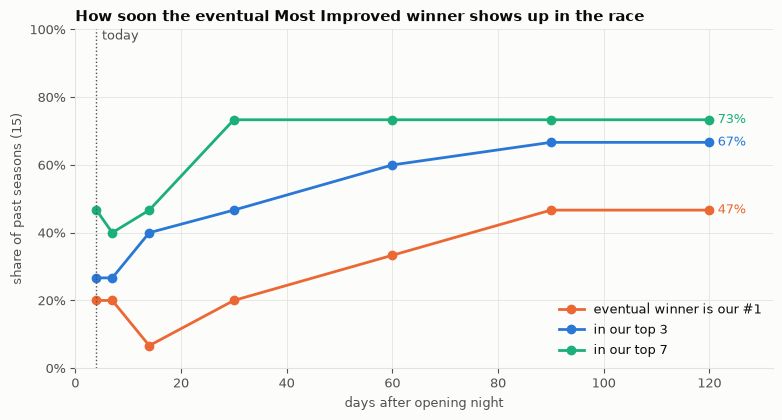

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.4))
n = len(ranks)
for (label, k), col in zip([("eventual winner is our #1", 1), ("in our top 3", 3), ("in our top 7", 7)], [ORANGE, BLUE, SERIES[2]]):
    share = [(ranks[d] <= k).sum() / n for d in DAYS]
    ax.plot(DAYS, share, marker="o", color=col, label=label)
    ax.annotate(f"{share[-1]:.0%}", (DAYS[-1], share[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=col)
ax.axvline(DAY_NOW, color=INK2, linewidth=1, linestyle=":")
ax.annotate("today", (DAY_NOW, 0.97), xytext=(4, 0), textcoords="offset points", fontsize=9, color=INK2)
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_xlim(0, DAYS[-1] + 12)
ax.set_xlabel("days after opening night"); ax.set_ylabel(f"share of past seasons ({n})")
ax.legend(frameon=False, loc="lower right")
ax.set_title("How soon the eventual Most Improved winner shows up in the race", loc="left")
fig.savefig(FIG_DIR / "10_2_race_by_day.png", dpi=150, bbox_inches="tight")

### 10.2A findings

- **After two days (one game for most teams), the race says very little.** The eventual winner was in our top 7 in 4 of 15 past seasons, in the top 3 once, and never #1. Median rank 19.
- **That is no better than the preseason prediction** in notebook 10.1 (winner in its top 7 in 4 of 14 seasons). One game adds about as much as a preseason.
- **It sharpens quickly.** By day 14 (about 6–7 games) the winner is in the top 7 in 7 of 15 seasons; by **day 30 (about 14 games) in 11 of 15, median rank 4.** After that the top 7 stops improving; what changes is the order at the top (#1 in 7 of 15 by day 90).
- **Rule of thumb:** treat the race as noise for the first two weeks, as a real shortlist after a month, and as a real ranking from about the All-Star break.

## 10.2B — The race today

In [5]:
hist, T = now[now["season"] != LIVE], now[now["season"] == LIVE].copy()
model = ChoiceModel(EARLY, L2).fit(hist)
T["chance"] = model.predict_proba(T)
T = T.sort_values("chance", ascending=False).reset_index(drop=True)
T["rank"] = np.arange(1, len(T) + 1)

NICE = {"ppg_delta": "points", "rpg_delta": "rebounds", "apg_delta": "assists", "spg_delta": "steals", "bpg_delta": "blocks",
        "mpg_delta": "minutes", "game_score_delta": "game score", "ts_delta": "shooting efficiency", "ppg_rel": "points (relative)",
        "game_score_rel": "game score (relative)", "team_win_delta": "team winning more", "age": "age", "second_year": "second-year discount"}
Z = pd.DataFrame(model._design(T), index=T.index, columns=EARLY)
contrib = ((Z - Z.mean()) * model.coef_).rename(columns=NICE)
T["why"] = [" + ".join(contrib.drop(columns="second-year discount").loc[i].nlargest(2).index) for i in T.index]   # the discount is never a reason to pick someone
print("weights:", model.coefficients().rename(NICE).round(2).sort_values(ascending=False).to_dict())
cols = {"rank": "rank", "player_name": "player", "team": "team", "chance": "chance", "games": "games", "ppg": "points", "base_ppg": "points last season",
        "game_score": "game score", "base_game_score": "game score last season", "mpg": "minutes", "base_mpg": "minutes last season", "age": "age", "why": "main reasons"}
T.head(10)[list(cols)].rename(columns=cols).style.format({"chance": "{:.1%}"}, precision=1).hide(axis="index")

weights: {'points': 0.76, 'assists': 0.44, 'points (relative)': 0.3, 'team winning more': 0.27, 'blocks': 0.26, 'game score': 0.14, 'rebounds': 0.08, 'game score (relative)': 0.07, 'steals': 0.01, 'minutes': -0.12, 'shooting efficiency': -0.4, 'second-year discount': -0.73, 'age': -0.79}


rank,player,team,chance,games,points,points last season,game score,game score last season,minutes,minutes last season,age,main reasons
1,Ty Jerome,MEM,37.8%,2,36.5,12.5,28.2,10.7,32.0,19.9,29.6,points + assists
2,Walker Kessler,LAL,12.8%,2,24.0,11.1,25.6,14.0,32.5,30.1,25.5,points + blocks
3,Jaxson Hayes,UTA,2.7%,2,11.0,7.5,13.8,7.8,26.0,18.3,26.7,blocks + points
4,Ja'Kobe Walter,TOR,1.7%,2,8.5,7.5,8.0,6.1,23.5,20.4,22.4,age + assists
5,Terrence Shannon Jr,MIN,1.3%,2,11.5,5.6,7.5,3.8,21.0,12.4,26.5,points + points (relative)
6,Davion Mitchell,MIA,1.3%,3,17.0,9.3,14.4,9.4,34.3,28.6,28.4,points + assists
7,Yves Missi,NOP,1.3%,2,9.5,5.7,14.7,6.9,19.5,19.6,22.7,age + points
8,Scottie Barnes,TOR,1.1%,2,25.5,18.1,17.8,16.7,31.5,33.5,25.5,points + age
9,Zaccharie Risacher,DAL,1.0%,3,8.7,9.6,9.0,7.1,30.3,22.4,21.8,age + blocks
10,Sidy Cissoko,POR,0.9%,2,9.0,5.1,9.1,3.6,25.5,19.1,22.8,points + age


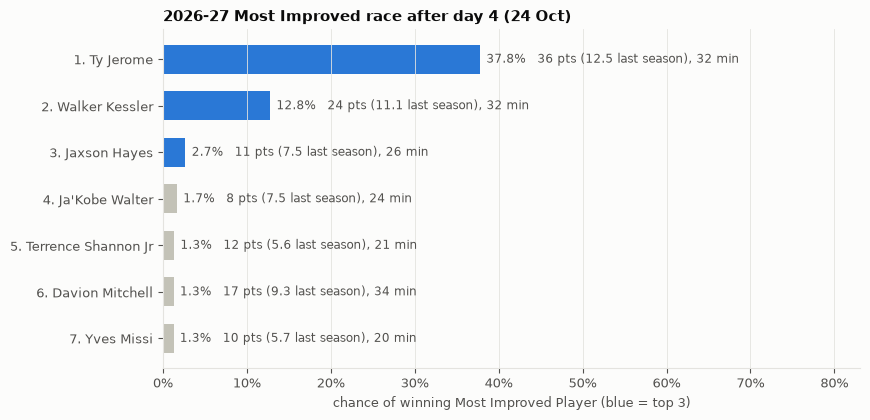

In [6]:
top = T.head(7).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(top))
ax.barh(y, top["chance"], color=[BLUE if r <= 3 else MUTED for r in top["rank"]], height=0.62)
for yi, (_, r) in zip(y, top.iterrows()):
    ax.text(r["chance"] + top["chance"].max() * 0.02, yi, f"{r['chance']:.1%}   {r['ppg']:.0f} pts ({r['base_ppg']:.1f} last season), {r['mpg']:.0f} min",
            va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, [f"{r['rank']}. {r['player_name']}" for _, r in top.iterrows()], fontsize=9.5)
ax.set_xlim(0, top["chance"].max() * 2.2); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="y", visible=False); ax.set_xlabel("chance of winning Most Improved Player (blue = top 3)")
ax.set_title(f"{LIVE} Most Improved race after day {DAY_NOW} ({live_games['game_date'].max():%d %b})", loc="left")
fig.savefig(FIG_DIR / "10_2_race_today.png", dpi=150, bbox_inches="tight")

In [7]:
# how our preseason top 7 (notebook 10.1, preseason through 12 Oct) has started
PRESEASON_TOP7 = ["Reed Sheppard", "Stephon Castle", "Ty Jerome", "Rui Hachimura", "Amen Thompson", "Leonard Miller", "Tristan da Silva"]
rows = []
for i, name in enumerate(PRESEASON_TOP7, 1):
    r = T[T["player_name"] == name]
    played = live_games[live_games["player_name"] == name]
    rows.append({"preseason rank": i, "player": name, "games": len(played),
                 "points": played["pts"].mean() if len(played) else np.nan,
                 "points last season": r["base_ppg"].iloc[0] if len(r) else np.nan,
                 "race rank now": int(r["rank"].iloc[0]) if len(r) else None, "chance now": f"{r['chance'].iloc[0]:.1%}" if len(r) else "not yet a candidate"})
pd.DataFrame(rows).set_index("preseason rank").round(1)

,player,games,points,points last season,race rank now,chance now
preseason rank,,,,,,
1,Reed Sheppard,2,11.0,13.5,15,0.7%
2,Stephon Castle,3,19.3,16.7,77,0.2%
3,Ty Jerome,2,36.5,12.5,1,37.8%
4,Rui Hachimura,2,13.0,11.5,43,0.4%
5,Amen Thompson,3,17.7,18.3,26,0.5%
6,Leonard Miller,3,10.0,7.8,21,0.6%
7,Tristan da Silva,2,9.5,9.9,73,0.2%


### 10.2B findings (after day 2, 22 October)

- **Ty Jerome leads clearly (about 20%).** He scored 45 points in 32 minutes against 12.5 points a game last season. He was #3 in our preseason top 7, and the only one of those seven to start hot. Age (29.6) is the main thing holding his chance down.
- **Behind him the field is wide open:** Yves Missi (about 6%), then Jabari Smith Jr., Paolo Banchero, Anthony Edwards, Ja'Kobe Walter and Walker Kessler, each 2–3%.
- **Our other preseason picks had quiet openers:** Reed Sheppard 3 points (85th now), Stephon Castle 24 points but from a higher base (94th).
- **What the model rewards this early:** a points jump (+0.64 per SD) and an assists jump (+0.43); it marks down age (−0.83) and second-year players (−0.65), as in notebook 10.

**Open decision (yours): the 22-point rule from 10.1.** It is not applied here, so established scorers can appear (Anthony Edwards, last season 28.8). Banchero sits right on that line (22.2). Applying it would make 10.1 and 10.2 consistent.

**Re-run** this notebook at any time; the first cell downloads the latest games.

## 10.2C — Three snapshots of the 2026-27 race, and the reasons behind each pick

Who did we think would rise most, at three points in time?

1. **End of 2025-26:** last season only (level, role, momentum, age). The 10.1 model without preseason inputs.
2. **End of preseason:** the 10.1 model, now with the **full** preseason (10.1 itself was run on preseason games through 12 October).
3. **Today:** the live race from 10.2B.

Snapshots 1 and 2 use 10.1's candidate rules (no previous winners, no players who averaged 22+ points last season) and its pool (players who appeared in preseason). Snapshot 3 uses 10.2's rules, so established scorers can appear.

**Reasons** are shown two ways: the inputs that pushed each player up most in each model, and plain facts about his situation (role, minutes, points, rebounds, opportunity). The facts are descriptive; "opportunity" (minutes that left his team over the summer) is **not** a model input.

In [8]:
# SNAPSHOTS
from unicorn.preseason import LAST_SEASON_LEAN, LEAN, MOMENTUM, PROFILE, add_pool_flags, load_preseason, preseason_frame

past_games = games[games["season"] != LIVE]
pre = load_preseason(regular=games, refresh_latest=True)            # complete 2026-27 preseason
pre_now = pre[pre["season"] == LIVE]
print(f"{LIVE} preseason: {pre_now['game_id'].nunique()} games, {pre_now['game_date'].min():%d %b} → {pre_now['game_date'].max():%d %b}")

F = add_pool_flags(preseason_frame(pre, past_games, ps), MIP_WINNERS)
F["candidate"] = ~F["previous_winner"] & (F["ppg_last"] < 22)
FH = F[(F["season"] != LIVE) & F["candidate"]].reset_index(drop=True)
FT = F[(F["season"] == LIVE) & F["candidate"]].reset_index(drop=True)

NICE_PRE = {"mpg_last": "minutes last season", "ppg_last": "points last season", "usg_last": "usage last season",
            "team_win_pct_last": "team's wins last season", "age": "age", "second_year": "second-year discount", "new_team": "new team",
            "momentum_game_score": "improved last season", "late_surge_last": "strong finish last season",
            "pre_game_score_change": "preseason production per 36", "pre_volume_change": "preseason shot volume per 36",
            "pre_ts_change": "preseason shooting"}

def snapshot(train, test, features, nice):
    m = ChoiceModel(features, L2).fit(train)
    out = test[["player_id", "player_name"]].copy()
    out["chance"] = m.predict_proba(test)
    out["rank"] = out["chance"].rank(ascending=False, method="first").astype(int)
    Z = pd.DataFrame(m._design(test), index=test.index, columns=features)
    c = ((Z - Z.mean()) * m.coef_).rename(columns=nice)
    out["model reasons"] = [", ".join(c.drop(columns="second-year discount").loc[i].nlargest(2).index) for i in test.index]
    return out.set_index("player_id")

S1 = snapshot(FH, FT, LAST_SEASON_LEAN + PROFILE + MOMENTUM, NICE_PRE)
S2 = snapshot(FH, FT, LEAN, NICE_PRE)
S3 = T.set_index("player_id")[["player_name", "chance", "rank", "why"]].rename(columns={"why": "model reasons"})
snaps = {"end of 2025-26": S1, "end of preseason": S2, "today": S3}
for name, s in snaps.items():
    print(f"\n{name}: " + ", ".join(f"{r.player_name} {r.chance:.1%}" for r in s.sort_values("rank").head(7).itertuples()))

2026-27 preseason: 67 games, 03 Oct → 16 Oct



end of 2025-26: Jalen Duren 6.8%, Amen Thompson 4.5%, Stephon Castle 4.1%, Tyrese Haliburton 3.3%, Reed Sheppard 2.2%, LaMelo Ball 2.0%, Jabari Smith Jr. 1.7%

end of preseason: Jalen Duren 15.6%, Tyrese Haliburton 12.4%, Tristan da Silva 4.4%, Ty Jerome 3.3%, Leonard Miller 3.1%, Rui Hachimura 2.9%, Reed Sheppard 2.6%

today: Ty Jerome 37.8%, Walker Kessler 12.8%, Jaxson Hayes 2.7%, Ja'Kobe Walter 1.7%, Terrence Shannon Jr 1.3%, Davion Mitchell 1.3%, Yves Missi 1.3%


In [9]:
# plain facts for every player who made any of the three top 7s
ids = sorted({pid for s in snaps.values() for pid in s.index[s["rank"] <= 7]})
last = past_games[past_games["season_start"] == LIVE_START - 1]
last_team = last.sort_values("game_date").groupby("player_id")["team_id"].last()
last_min = last.groupby("player_id")["min"].sum()
# "baseline season" = the season every model compares against (most recent with 33%+ of the games), not always 2025-26
by_season = past_games.groupby(["player_id", "season_start"]).agg(ppg=("pts", "mean"), rpg=("reb", "mean"), mpg=("min", "mean"))
base_start = F[F["season"] == LIVE].set_index("player_id")["base_season_start"]
L = by_season.reindex(list(zip(base_start.index, base_start.astype(int)))).set_axis(base_start.index)
cur_team = pd.concat([pre_now.sort_values("game_date").groupby("player_id")["team_id"].last(),
                      live_games.sort_values("game_date").groupby("player_id")["team_id"].last()]).groupby(level=0).last()

# opportunity: last season's minutes (per team game) that left each team, minus minutes that arrived
moved = pd.DataFrame({"from": last_team, "to": cur_team.reindex(last_team.index), "min": last_min})
left = moved[moved["from"] != moved["to"]].groupby("from")["min"].sum() / 82      # includes players not seen this season
arrived = moved[moved["to"].notna() & (moved["from"] != moved["to"])].groupby("to")["min"].sum() / 82
net_open = left.sub(arrived, fill_value=0)

pre_rows = F[F["season"] == LIVE].set_index("player_id")
live_rows = T.set_index("player_id")
facts = []
for pid in ids:
    f = pre_rows.loc[pid] if pid in pre_rows.index else None
    l = L.loc[pid] if pid in L.index else None
    t = live_rows.loc[pid] if pid in live_rows.index else None
    name = next(s.loc[pid, "player_name"] for s in snaps.values() if pid in s.index)
    row = {"player": name, **{f"rank: {k}": (int(s.loc[pid, "rank"]) if pid in s.index else np.nan) for k, s in snaps.items()},
           "age": f["age"] if f is not None else (t["age"] if t is not None else np.nan),
           "baseline season": int(base_start[pid]) if pid in base_start.index else np.nan,
           "baseline: points": l["ppg"] if l is not None else np.nan, "baseline: rebounds": l["rpg"] if l is not None else np.nan,
           "baseline: minutes": l["mpg"] if l is not None else np.nan,
           "baseline: usage %": 100 * f["usg_last"] if f is not None else np.nan,
           "baseline: started %": 100 * f["start_rate_last"] if f is not None else np.nan,
           "improved last season (game score)": f["momentum_game_score"] if f is not None else np.nan,
           "finish vs start of last season (game score)": f["late_surge_last"] if f is not None else np.nan,
           "preseason: minutes": f["pre_mpg"] if f is not None else np.nan,
           "preseason: points per 36 vs last season": (f["pts36"] - f["pts36_last"]) if f is not None else np.nan,
           "preseason: shots per 36 vs last season": (f["volume36"] - f["volume36_last"]) if f is not None else np.nan,
           "today: games": t["games"] if t is not None else 0,
           "today: points vs baseline": t["ppg_delta"] if t is not None else np.nan,
           "today: rebounds vs baseline": t["rpg_delta"] if t is not None else np.nan,
           "today: minutes vs baseline": t["mpg_delta"] if t is not None else np.nan,
           "changed team this summer": pid in cur_team.index and pid in last_team.index and cur_team[pid] != last_team[pid],
           "opportunity: net minutes freed on his team": net_open.get(cur_team.get(pid), np.nan)}
    facts.append(row)
facts = pd.DataFrame(facts).set_index("player").sort_values("rank: today")
facts.round(1)

,rank: end of 2025-26,rank: end of preseason,rank: today,age,baseline season,baseline: points,baseline: rebounds,baseline: minutes,baseline: usage %,baseline: started %,...,finish vs start of last season (game score),preseason: minutes,preseason: points per 36 vs last season,preseason: shots per 36 vs last season,today: games,today: points vs baseline,today: rebounds vs baseline,today: minutes vs baseline,changed team this summer,opportunity: net minutes freed on his team
player,,,,,,,,,,,,,,,,,,,,,
Ty Jerome,19,4,1,29.6,2024,12.5,2.5,19.9,22.9,4.3,...,2.2,17.5,9.1,8.2,2,24.0,2.0,12.1,False,17.0
Walker Kessler,130,149,2,25.5,2024,11.1,12.2,30.1,13.3,100.0,...,-1.3,23.5,-0.2,2.5,2,12.9,-3.7,2.4,True,36.9
Jaxson Hayes,85,124,3,26.7,2025,7.5,4.1,18.3,12.4,13.6,...,2.3,18.2,-2.0,3.0,2,3.5,0.9,7.7,True,33.5
Ja'Kobe Walter,71,92,4,22.4,2025,7.5,2.6,20.4,13.6,26.4,...,3.6,18.8,0.7,3.8,2,1.0,0.9,3.1,False,32.0
Terrence Shannon Jr,187,128,5,26.5,2025,5.6,1.1,12.4,17.1,4.7,...,2.6,16.4,3.5,4.8,2,5.9,1.4,8.6,False,58.9
Davion Mitchell,128,78,6,28.4,2025,9.3,2.7,28.6,13.7,100.0,...,0.2,18.0,4.2,5.5,3,7.7,-1.7,5.8,False,1.5
Yves Missi,268,232,7,22.7,2025,5.7,5.8,19.6,12.2,21.2,...,0.7,18.5,3.6,2.7,2,3.8,1.7,-0.1,False,-21.3
Reed Sheppard,5,7,15,22.6,2025,13.5,2.9,26.2,21.0,25.6,...,2.6,20.0,7.8,4.7,2,-2.5,1.1,-3.2,False,0.5
Jabari Smith Jr.,7,31,20,23.7,2025,15.8,6.9,35.1,17.9,100.0,...,0.9,23.0,-0.5,1.0,3,1.2,-1.9,-0.8,False,0.5


In [10]:
def tags(r):
    """Plain-language reasons from the facts table (descriptive thresholds, not model inputs)."""
    t = []
    if r["age"] < 24: t.append(f"young ({r['age']:.0f})")
    if r["baseline: minutes"] >= 30: t.append(f"already {r['baseline: minutes']:.0f} min")
    elif r["baseline: minutes"] < 20: t.append(f"bench role last season ({r['baseline: minutes']:.0f} min)")
    if r["baseline: started %"] < 25: t.append("came off the bench")
    if r["improved last season (game score)"] >= 1.5: t.append("improving already")
    if r["finish vs start of last season (game score)"] >= 1.5: t.append("strong finish to last season")
    if r["preseason: minutes"] - r["baseline: minutes"] >= 4: t.append(f"preseason minutes up ({r['preseason: minutes']:.0f})")
    if r["preseason: shots per 36 vs last season"] >= 3: t.append("shooting more in preseason")
    if r["changed team this summer"]: t.append("new team")
    if r["opportunity: net minutes freed on his team"] >= 40: t.append(f"{r['opportunity: net minutes freed on his team']:.0f} min/game left his team")
    if r["today: points vs baseline"] >= 5: t.append(f"+{r['today: points vs baseline']:.0f} points so far")
    if r["today: rebounds vs baseline"] >= 3: t.append(f"+{r['today: rebounds vs baseline']:.0f} rebounds so far")
    if r["today: minutes vs baseline"] >= 6: t.append(f"+{r['today: minutes vs baseline']:.0f} minutes so far")
    return " · ".join(t)

facts["situation"] = facts.apply(tags, axis=1)
reasons = pd.DataFrame({f"why {k}": [s.loc[pid, "model reasons"] if pid in s.index else "" for pid in ids] for k, s in snaps.items()},
                       index=[facts.index[list(facts.index).index(n)] for n in [next(s.loc[pid, 'player_name'] for s in snaps.values() if pid in s.index) for pid in ids]])
facts.join(reasons)[["rank: end of 2025-26", "rank: end of preseason", "rank: today", "situation", *reasons.columns]]

,rank: end of 2025-26,rank: end of preseason,rank: today,situation,why end of 2025-26,why end of preseason,why today
player,,,,,,,
Ty Jerome,19,4,1,bench role last season (20 min) · came off the...,"team's wins last season, new team","preseason shot volume per 36, team's wins last...",points + assists
Walker Kessler,130,149,2,already 30 min · improving already · new team ...,"minutes last season, new team","minutes last season, new team",points + blocks
Jaxson Hayes,85,124,3,bench role last season (18 min) · came off the...,"strong finish last season, team's wins last se...","new team, strong finish last season",blocks + points
Ja'Kobe Walter,71,92,4,young (22) · strong finish to last season · sh...,"strong finish last season, age","strong finish last season, age",age + assists
Terrence Shannon Jr,187,128,5,bench role last season (12 min) · came off the...,"strong finish last season, team's wins last se...","preseason shot volume per 36, strong finish la...",points + points (relative)
Davion Mitchell,128,78,6,improving already · shooting more in preseason...,"minutes last season, improved last season","preseason shot volume per 36, minutes last season",points + assists
Yves Missi,268,232,7,young (23) · bench role last season (20 min) ·...,"age, strong finish last season","age, preseason shot volume per 36",age + points
Reed Sheppard,5,7,15,young (23) · improving already · strong finish...,"improved last season, age","preseason shot volume per 36, improved last se...",age + assists
Jabari Smith Jr.,7,31,20,young (24) · already 35 min · improving already,"minutes last season, age","minutes last season, age",age + team winning more


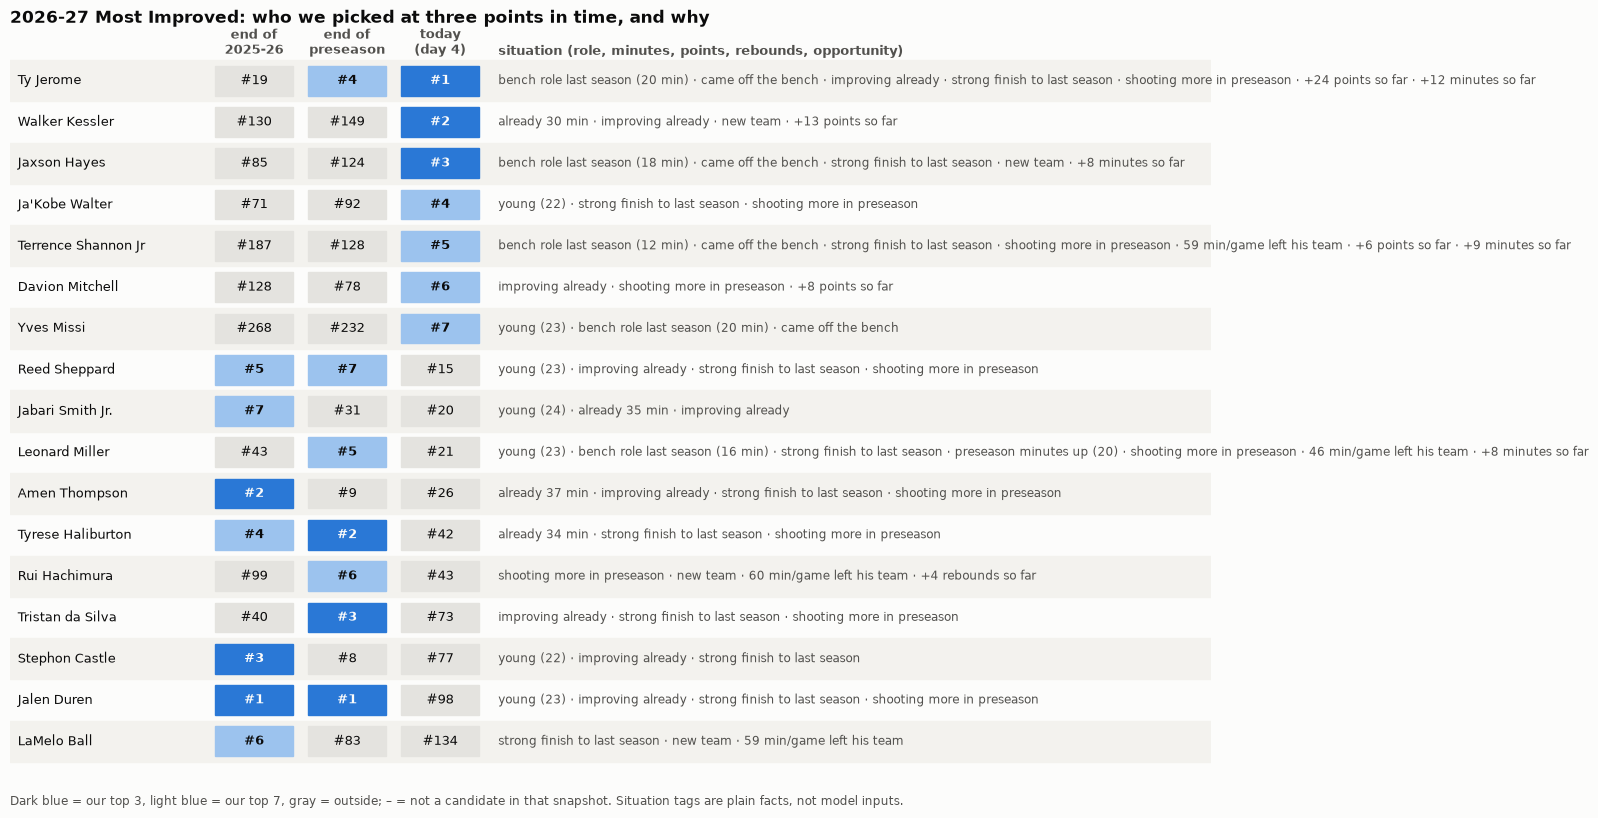

In [11]:
fig_rows = facts.sort_values(["rank: today"]).copy()
n = len(fig_rows)
fig, ax = plt.subplots(figsize=(15.5, 0.48 * n + 1.6))
ax.set_xlim(0, 15.5); ax.set_ylim(n, -1.2); ax.axis("off")
cols_x = {"end of 2025-26": 3.15, "end of preseason": 4.35, "today": 5.55}
for x, label in zip(cols_x.values(), ["end of\n2025-26", "end of\npreseason", f"today\n(day {DAY_NOW})"]):
    ax.text(x, -0.55, label, ha="center", va="bottom", fontsize=9, color=INK2, fontweight="bold")
ax.text(6.3, -0.55, "situation (role, minutes, points, rebounds, opportunity)", ha="left", va="bottom", fontsize=9, color=INK2, fontweight="bold")
for i, (name, r) in enumerate(fig_rows.iterrows()):
    if i % 2 == 0:
        ax.add_patch(plt.Rectangle((0, i - 0.5), 15.5, 1, color="#f3f2ee", zorder=0))
    ax.text(0.1, i, name, va="center", fontsize=9.5, color=INK)
    for k, x in cols_x.items():
        rk = r[f"rank: {k}"]
        top = pd.notna(rk) and rk <= 7
        ax.add_patch(plt.Rectangle((x - 0.5, i - 0.36), 1.0, 0.72, color=(BLUE if pd.notna(rk) and rk <= 3 else "#9cc3ee" if top else "#e4e3df"), zorder=1))
        ax.text(x, i, "–" if pd.isna(rk) else f"#{int(rk)}", ha="center", va="center", fontsize=9, zorder=2,
                color=SURFACE if pd.notna(rk) and rk <= 3 else INK, fontweight="bold" if top else "normal")
    ax.text(6.3, i, r["situation"], va="center", fontsize=8.3, color=INK2)
ax.set_title(f"{LIVE} Most Improved: who we picked at three points in time, and why", loc="left", fontsize=12, x=0)
ax.text(0, n + 0.3, "Dark blue = our top 3, light blue = our top 7, gray = outside; – = not a candidate in that snapshot. "
        "Situation tags are plain facts, not model inputs.", fontsize=8.5, color=INK2, va="top")
fig.savefig(FIG_DIR / "10_2_three_snapshots.png", dpi=150, bbox_inches="tight")

### 10.2C findings (day 4, 24 October; teams have played 2–3 games)

**End of 2025-26: young players already playing big minutes and already improving.** Jalen Duren, Amen Thompson, Stephon Castle, Tyrese Haliburton, Reed Sheppard, LaMelo Ball, Jabari Smith Jr. The common thread is "improving already" and "strong finish to last season"; most were 23–24 with 28+ minutes. This model has no information about the summer, so it can only extend last season's trend.

**End of preseason: the preseason reshuffles the middle, not the top.** Duren stays #1 and Haliburton climbs to #2, both on big preseason shot volume. Tristan da Silva, Ty Jerome, Leonard Miller and Rui Hachimura come in on preseason shooting volume. Thompson, Castle and Smith drop because their preseason was ordinary. Reed Sheppard is the only player in the top 7 at both of the first two points.
- This differs from 10.1's list (made on preseason games through 12 October) because Duren and Haliburton had not yet played a preseason game then.

**Today: almost a new list.** Six of today's top 7 were outside the top 75 at both earlier points (Walker Kessler, Jaxson Hayes, Ja'Kobe Walter, Terrence Shannon Jr, Davion Mitchell, Yves Missi). Only **Ty Jerome** made both the preseason and today top 7. He is the only clear leader (38%); after Kessler (13%) everyone is under 3%.
- **Duren has started badly** (6.5 points and 9.3 minutes a game below his baseline) and is now 98th.
- 10.2A says what to make of this: at this point the eventual winner has been in our top 7 in only about a quarter of past seasons. **The earlier lists are not wrong yet; there isn't enough evidence to overrule them.**

**Reasons, by type**
- **Role:** the risers so far mostly came off the bench last season (Jerome, Hayes, Shannon, Missi). The earlier lists favoured players who already started and played 30+ minutes.
- **Minutes:** today's movers have mostly gained minutes (Jerome +12, Shannon +9, Hayes +8). Points follow minutes this early.
- **Points and rebounds:** the model's early weights are on a points jump and an assists jump. Rebounds barely count (Hachimura +4 rebounds so far, still 43rd).
- **Opportunity:** a lot of minutes left Terrence Shannon Jr's team (59 a game), Rui Hachimura's (60), LaMelo Ball's (59) and Leonard Miller's (46) over the summer. This counts every departed player, including anyone injured but still on the roster who simply hasn't played yet, so treat it as a rough signal. It is not a model input; it could be tested as one.